# Adaptive Runge–Kuttaと局所誤差制御

## 概要

適応Runge–Kutta法は、各ステップで誤差を推定し、時間刻みを調整する常微分方程式の数値解法である。この記事では、3次と2次の公式を組み合わせるBogacki–Shampine法を実装し、誤差の正規化、ステップの採用と棄却、許容誤差と計算量の関係を確認する。厳密解との比較から、局所誤差と大域誤差の違いも扱う。

## 実行環境

Pythonは **3.14.6**、Jupyterのカーネル名は **wa-src(3.14.6)** である。NumPy、SciPy、MatplotlibとIPythonを使用する。セルを上から順に実行する。図はノートブック内に表示し、`107_nb_files` にSVG形式で保存する。数値の表示は有効数字3桁にそろえ、内部の計算値は丸めない。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Math, SVG, display
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy.integrate import solve_ivp
from scipy.special import erf

print('カーネル: wa-src(3.14.6)')
print('Python:', platform.python_version())
print('実行ファイル:', sys.executable)
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('Matplotlib:', matplotlib.__version__)
assert sys.version_info[:3] == (3, 14, 6)

# リポジトリ直下とノートブックのフォルダーからの実行に対応する。
base = Path('rec/computing/107')
fig_dir = (base if base.is_dir() else Path.cwd()) / '107_nb_files'
fig_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'svg.fonttype': 'none',
                     'svg.hashsalt': 'rk107', 'axes.grid': True})


def sig(value):
    return f'{float(value):#.3g}'


np.set_printoptions(formatter={'float_kind': sig})


def save_figure(fig, name):
    # 目盛りも有効数字3桁にし、同じ図を保存・表示する。
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda x, pos: sig(x)))
            axis.set_minor_formatter(NullFormatter())
        ax.grid(True, alpha=0.250)
    path = fig_dir / name
    fig.savefig(path, format='svg', bbox_inches='tight',
                metadata={'Date': None})
    plt.close(fig)
    display(SVG(filename=str(path)))

カーネル: wa-src(3.14.6)
Python: 3.14.6
実行ファイル: /Users/hiroshi/private/wa_src/.venv/bin/python
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2


## 1. 1ステップの誤差と積分全体の誤差

初期値問題を

$$
\frac{d\mathbf{y}}{dt}=\mathbf{f}(t,\mathbf{y}),
\qquad \mathbf{y}(t_0)=\mathbf{y}_0
$$

とする。$h_n=t_{n+1}-t_n$ とし、出発値 $\mathbf{v}$ から厳密に1ステップ進める写像を $\mathbf{\Phi}_{h_n}(t_n,\mathbf{v})$ と書く。数値計算の出発値を正確とみなしたときの誤差が局所誤差である。ここでは $h_n$ で割らない定義を使う。

$$
\mathbf{d}_{n+1}=\mathbf{\Phi}_{h_n}(t_n,\mathbf{y}_n)-\mathbf{y}_{n+1},
\qquad
\mathbf{E}_n=\mathbf{y}(t_n)-\mathbf{y}_n.
$$

$\mathbf{E}_n$ は初期時刻から蓄積した大域誤差である。両者の関係は、同じ項を加えて引くと分かる。

$$
\begin{aligned}
\mathbf{E}_{n+1}
&=\mathbf{\Phi}_{h_n}(t_n,\mathbf{y}(t_n))-\mathbf{y}_{n+1}\\
&=\left[\mathbf{\Phi}_{h_n}(t_n,\mathbf{y}(t_n))
-\mathbf{\Phi}_{h_n}(t_n,\mathbf{y}_n)\right]+\mathbf{d}_{n+1}.
\end{aligned}
$$

右辺の角括弧は、それまでの誤差が次の時刻へ伝わる項である。十分な滑らかさと安定性の下で、$p$ 次法の局所誤差は $O(h^{p+1})$、固定区間の大域誤差は $O(h^p)$ となる。局所誤差を小さくしても、大域誤差が同じ許容値以内になる保証はない。

## 2. 埋め込みRunge–Kutta法

陽的Runge–Kutta法は傾き $\mathbf{k}_i$ を順番に計算する。

$$
\mathbf{k}_i=\mathbf{f}\left(t_n+c_i h,
\mathbf{y}_n+h\sum_{j<i}a_{ij}\mathbf{k}_j\right),\qquad
\mathbf{y}_{n+1}^{(p)}=\mathbf{y}_n+h\sum_i b_i\mathbf{k}_i.
$$

同じ傾きに別の重み $\widehat b_i$ を使うと、低い次数の近似も得られる。その差を誤差推定に利用する。

### Bogacki–Shampineの3(2)公式

[SciPyのRK23](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.RK23.html)でも使われる公式である。以下では1ステップ分の添字 $n+1$ を省略する。

$$
\begin{aligned}
\mathbf{k}_1&=\mathbf{f}(t_n,\mathbf{y}_n),\\
\mathbf{k}_2&=\mathbf{f}\left(t_n+\frac{h}{2},\mathbf{y}_n+\frac{h}{2}\mathbf{k}_1\right),\\
\mathbf{k}_3&=\mathbf{f}\left(t_n+\frac{3h}{4},\mathbf{y}_n+\frac{3h}{4}\mathbf{k}_2\right),\\
\mathbf{y}^{(3)}&=\mathbf{y}_n+h\left(\frac{2}{9}\mathbf{k}_1+\frac{1}{3}\mathbf{k}_2+\frac{4}{9}\mathbf{k}_3\right),\\
\mathbf{k}_4&=\mathbf{f}(t_n+h,\mathbf{y}^{(3)}),\\
\mathbf{y}^{(2)}&=\mathbf{y}_n+h\left(\frac{7}{24}\mathbf{k}_1+\frac{1}{4}\mathbf{k}_2+\frac{1}{3}\mathbf{k}_3+\frac{1}{8}\mathbf{k}_4\right).
\end{aligned}
$$

係数の差は $2/9-7/24=-5/72$、$1/3-1/4=1/12$、$4/9-1/3=1/9$ である。したがって推定値は次になる。

<div>
$$
\boxed{\mathbf{e}=\mathbf{y}^{(3)}-\mathbf{y}^{(2)}
=h\left(-\frac{5}{72}\mathbf{k}_1+\frac{1}{12}\mathbf{k}_2
+\frac{1}{9}\mathbf{k}_3-\frac{1}{8}\mathbf{k}_4\right)}
$$
</div>

厳密な1ステップ後の値を $\mathbf{Y}$ とすると、

$$
\mathbf{e}=(\mathbf{Y}-\mathbf{y}^{(2)})-(\mathbf{Y}-\mathbf{y}^{(3)})
=O(h^3)-O(h^4)=O(h^3).
$$

この差が推定するのは主に**2次公式の局所誤差**である。採用する値は3次公式だが、刻みの更新には $h^3$ の関係を使う。

In [2]:
def bs23_step(fun, t, y, h, k1=None):
    # k1を再利用すると、追加の関数評価は3回で済む。
    if k1 is None:
        k1 = fun(t, y)
    k2 = fun(t + h / 2, y + h * k1 / 2)
    k3 = fun(t + 3 * h / 4, y + 3 * h * k2 / 4)
    y3 = y + h * (2 * k1 / 9 + k2 / 3 + 4 * k3 / 9)
    k4 = fun(t + h, y3)
    # 近い値y3とy2を直接引かず、係数の差から推定値を計算する。
    error = h * (-5 * k1 / 72 + k2 / 12 + k3 / 9 - k4 / 8)
    return y3, error, k4

### $y'=-y$ で次数を確かめる

$y(0)=1$ から1ステップ進める。各傾きを代入すると、

$$
\begin{aligned}
k_1&=-1,\qquad k_2=-\left(1-\frac h2\right)=-1+\frac h2,\\
k_3&=-\left(1+\frac{3h}{4}\left(-1+\frac h2\right)\right)
=-1+\frac{3h}{4}-\frac{3h^2}{8},\\
y^{(3)}&=1+h\left[-\frac29+\frac13\left(-1+\frac h2\right)
+\frac49\left(-1+\frac{3h}{4}-\frac{3h^2}{8}\right)\right]\\
&=1-h+\frac{h^2}{2}-\frac{h^3}{6},\\
k_4&=-1+h-\frac{h^2}{2}+\frac{h^3}{6},\\
y^{(2)}&=1+h\left[-\frac7{24}+\frac14\left(-1+\frac h2\right)
+\frac13\left(-1+\frac{3h}{4}-\frac{3h^2}{8}\right)
+\frac18\left(-1+h-\frac{h^2}{2}+\frac{h^3}{6}\right)\right]\\
&=1-h+\frac{h^2}{2}-\frac{3h^3}{16}+\frac{h^4}{48}.
\end{aligned}
$$

両者を引き、厳密解 $e^{-h}$ の展開とも比べる。

$$
\begin{aligned}
e&=\left(-\frac16+\frac3{16}\right)h^3-\frac{h^4}{48}
=\frac{h^3(1-h)}{48},\\
e^{-h}-y^{(3)}
&=\left(1-h+\frac{h^2}{2}-\frac{h^3}{6}+\frac{h^4}{24}+O(h^5)\right)
-\left(1-h+\frac{h^2}{2}-\frac{h^3}{6}\right)\\
&=\frac{h^4}{24}+O(h^5).
\end{aligned}
$$

対数グラフでは推定値の傾きが3、3次解の局所誤差の傾きが4に近づく。一方、$h=1$ では推定値が0でも真の誤差は0ではない。推定は小さい刻みで成り立つ近似であり、誤差の厳密な上限ではない。

{'3次解の局所誤差の次数': '4.00', '推定値の次数': '3.00'}


<IPython.core.display.Math object>

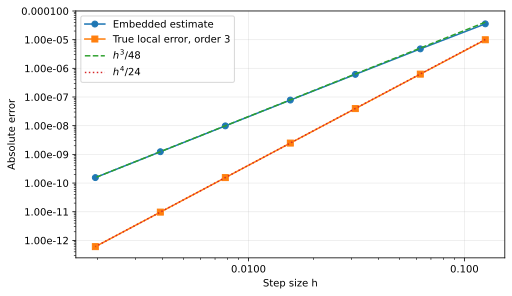

In [3]:
hs = 2.00 ** (-np.arange(3, 10))
estimates, defects = [], []
for h in hs:
    y3, e, _ = bs23_step(lambda t, y: -y, 0, np.array([1.00]), h)
    estimates.append(abs(e[0]))
    defects.append(abs(np.exp(-h) - y3[0]))
estimates, defects = np.array(estimates), np.array(defects)
pprint({'推定値の次数': sig(np.log2(estimates[-2] / estimates[-1])),
        '3次解の局所誤差の次数': sig(np.log2(defects[-2] / defects[-1]))})
display(Math(r'e=\frac{h^3(1-h)}{48},\qquad d^{(3)}=\frac{h^4}{24}+O(h^5)'))

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.loglog(hs, estimates, 'o-', label='Embedded estimate')
ax.loglog(hs, defects, 's-', label='True local error, order 3')
ax.loglog(hs, hs**3 / 48, '--', label=r'$h^3/48$')
ax.loglog(hs, hs**4 / 24, ':', label=r'$h^4/24$')
ax.set(xlabel='Step size h', ylabel='Absolute error')
ax.legend()
save_figure(fig, '01_local_order.svg')

## 3. 許容誤差と刻み幅の更新

成分 $i$ の許容尺度を、絶対許容誤差と相対許容誤差から作る。

$$
s_i=\mathrm{atol}_i+\mathrm{rtol}\max(|y_{n,i}|,|y_i^{(3)}|),
\qquad r_i=\frac{|e_i|}{s_i},\qquad R=\max_i r_i.
$$

ここでは $R\leq1$ なら採用し、$R>1$ なら時刻も状態も進めずに再計算する。$y_i$ が0に近いときは `atol` が効く。単位や大きさが異なる成分には、成分別の `atol` を設定する。

尺度と誤差係数が次の試行でもほぼ同じなら、$R\simeq Ch^{q+1}$ と置ける。目標を1として、

$$
\frac{R_{\mathrm{new}}}{R}\simeq
\left(\frac{h_{\mathrm{new}}}{h}\right)^{q+1},\qquad
\frac1R\simeq\left(\frac{h_{\mathrm{new}}}{h}\right)^{q+1},\qquad
\frac{h_{\mathrm{new}}}{h}\simeq R^{-1/(q+1)}.
$$

3(2)公式では $q=2$ である。安全係数 $0.900$ と増減の制限を加える。

<div>
$$
\boxed{h_{\mathrm{new}}=h\,\min\left(5,\max\left(0.200,0.900R^{-1/3}\right)\right)}
$$
</div>

$R=0$ なら倍率を5とする。棄却直後の採用では倍率を1以下に抑える。私は結果の曲線だけでなく、棄却回数と刻み幅も確認する方が計算の状態を把握しやすいと感じる。

以下は前進積分、実数の1次元配列、正の許容値を対象とする実装である。採用後の $\mathbf{k}_4$ は次の $\mathbf{k}_1$ と一致するため再利用する。この性質はFSALと呼ばれ、試行数を $N$ とすると関数評価回数は $1+3N$ になる。

In [4]:
def adaptive_bs23(fun, span, y0, rtol=1.00e-5, atol=1.00e-8,
                  h0=0.500, max_step=1.00, max_trials=100000):
    t, end = map(float, span)
    y = np.asarray(y0, dtype=float).copy()
    if y.ndim != 1 or y.size == 0 or not np.all(np.isfinite(y)):
        raise ValueError('y0は有限な実数の1次元配列とする')
    atol = np.broadcast_to(np.asarray(atol, dtype=float), y.shape)
    values = np.r_[t, end, rtol, h0, max_step, atol]
    if (not np.all(np.isfinite(values)) or end <= t or rtol <= 0
            or h0 <= 0 or max_step <= 0 or np.any(atol <= 0)):
        raise ValueError('有限な区間と正の許容値・刻み幅が必要である')
    ts, ys, trials = [t], [y.copy()], []
    h, nfev, rejected = min(h0, max_step), 1, False
    k1 = fun(t, y)
    for _ in range(max_trials):
        if t >= end:
            break
        # 終端を越えず、丸めで時刻が進まない場合は停止する。
        next_t = min(t + min(h, max_step), end)
        h = next_t - t
        if h <= 0:
            raise RuntimeError('刻み幅が小さすぎて時刻を更新できない')
        candidate, error, k4 = bs23_step(fun, t, y, h, k1)
        nfev += 3
        scale = atol + rtol * np.maximum(abs(y), abs(candidate))
        ratio = float(np.max(abs(error) / scale))
        if not np.isfinite(ratio) or not np.all(np.isfinite(candidate)):
            raise FloatingPointError('解または誤差推定値が有限でない')
        accepted = ratio <= 1
        trials.append((t, h, ratio, accepted))
        factor = 5 if ratio == 0 else np.clip(0.900 * ratio**(-1 / 3), 0.200, 5)
        if accepted:
            if rejected:
                factor = min(1, factor)
            t, y, k1 = next_t, candidate, k4
            ts.append(t)
            ys.append(y.copy())
            rejected = False
        else:
            # 棄却時はt、y、k1を保持する。
            rejected = True
        h *= factor
    if t < end:
        raise RuntimeError('最大試行回数に達した')
    return {'t': np.array(ts), 'y': np.array(ys),
            'trials': np.array(trials), 'nfev': nfev}

## 4. 変化の速い区間で刻みがどう変わるか

次の減衰方程式は $t=3$ 付近で減衰率が増える。

$$
y'=-a(t)y,\qquad a(t)=1+20e^{-25(t-3)^2},\qquad y(0)=1.
$$

変数分離により $\log y(t)=-\int_0^t a(s)\,ds=-A(t)$ となる。$u=5(s-3)$、$ds=du/5$ と置き、$\mathrm{erf}(x)=2\int_0^x e^{-u^2}\,du/\sqrt\pi$ を使う。

$$
\begin{aligned}
A(t)&=t+20\int_0^t e^{-25(s-3)^2}\,ds\\
&=t+4\int_{-15}^{5(t-3)}e^{-u^2}\,du\\
&=t+2\sqrt\pi\left[\mathrm{erf}(5(t-3))-\mathrm{erf}(-15)\right],\\
y(t)&=e^{-A(t)}.
\end{aligned}
$$

$0\leq t\leq6$ を計算する。初期刻みを $0.500$ として、棄却も記録する。

{'採用': 143, '棄却': 14, '節点上の最大絶対誤差': '6.15e-06', '関数評価': 472}


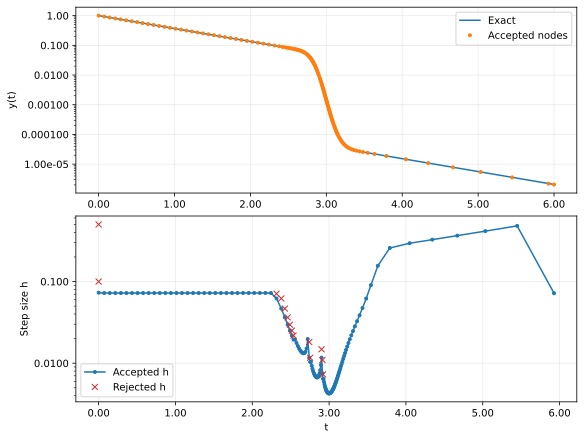

In [5]:
def integral_rate(t):
    return t + 2 * np.sqrt(np.pi) * (erf(5 * (t - 3)) - erf(-15))


def exact(t):
    return np.exp(-integral_rate(t))


def rhs(t, y):
    return -(1 + 20 * np.exp(-25 * (t - 3)**2)) * y


run = adaptive_bs23(rhs, (0, 6), [1.00])
t, y = run['t'], run['y'][:, 0]
trial = run['trials']
accepted = trial[:, 3].astype(bool)
global_error = abs(y - exact(t))
pprint({'採用': len(t) - 1, '棄却': int((~accepted).sum()),
        '関数評価': run['nfev'], '節点上の最大絶対誤差': sig(global_error.max())})

grid = np.linspace(0, 6, 1201)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), layout='constrained')
axes[0].semilogy(grid, exact(grid), label='Exact')
axes[0].semilogy(t, y, '.', label='Accepted nodes')
axes[0].set(ylabel='y(t)')
axes[0].legend()
axes[1].semilogy(t[:-1], np.diff(t), '.-', label='Accepted h')
axes[1].semilogy(trial[~accepted, 0], trial[~accepted, 1], 'x',
                 color='tab:red', label='Rejected h')
axes[1].set(xlabel='t', ylabel='Step size h')
axes[1].legend()
save_figure(fig, '02_adaptive_steps.svg')

減衰率が増える付近で刻みが小さくなる。後半で解が十分小さくなると、絶対許容誤差の影響が強くなり刻みが増える。刻み幅は傾きの大きさだけで決まるわけではない。

この例では、数値解 $y_n$ を出発値とする厳密な1ステップも計算できる。

$$
\Phi_h(t_n,y_n)=y_n e^{-[A(t_n+h)-A(t_n)]},\qquad
d_{n+1}=y_n e^{-[A(t_{n+1})-A(t_n)]}-y_{n+1}.
$$

次の図の上段では採否の判定値 $R$、下段では採用された3次解の真の局所誤差と大域誤差を比べる。0は対数軸に表示できないため、その点だけ除く。

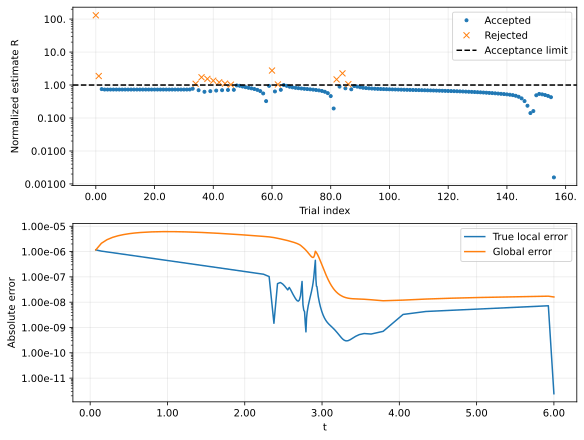

In [6]:
local_error = abs(y[:-1] * np.exp(-np.diff(integral_rate(t))) - y[1:])
fig, axes = plt.subplots(2, 1, figsize=(8, 6), layout='constrained')
for mask, label, marker in [(accepted, 'Accepted', '.'), (~accepted, 'Rejected', 'x')]:
    positive = mask & (trial[:, 2] > 0)
    axes[0].semilogy(np.flatnonzero(positive), trial[positive, 2], marker, label=label)
axes[0].axhline(1, color='black', linestyle='--', label='Acceptance limit')
axes[0].set(xlabel='Trial index', ylabel='Normalized estimate R')
axes[0].legend()
for errors, label in [(local_error, 'True local error'), (global_error[1:], 'Global error')]:
    positive = errors > 0
    axes[1].semilogy(t[1:][positive], errors[positive], label=label)
axes[1].set(xlabel='t', ylabel='Absolute error')
axes[1].legend()
save_figure(fig, '03_error_control.svg')

## 5. 許容誤差と計算量

`rtol`を小さくし、`atol = rtol / 1000` として同じ問題を解く。比較する誤差は各実行の**採用節点上**の最大絶対誤差であり、区間全体の上限ではない。関数評価回数には棄却された試行も含める。

[{'rtol': '0.00100', '最大誤差': '0.00135', '関数評価': 127},
 {'rtol': '0.000100', '最大誤差': '7.33e-05', '関数評価': 247},
 {'rtol': '1.00e-05', '最大誤差': '6.15e-06', '関数評価': 472},
 {'rtol': '1.00e-06', '最大誤差': '5.72e-07', '関数評価': 949},
 {'rtol': '1.00e-07', '最大誤差': '5.52e-08', '関数評価': 1990}]


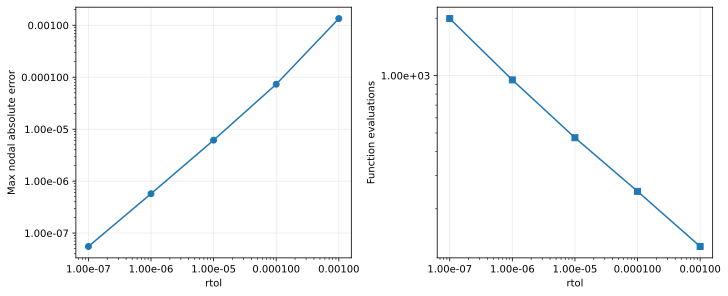

In [7]:
rtols = np.logspace(-3, -7, 5)
errors, costs, rows = [], [], []
for tol in rtols:
    result = adaptive_bs23(rhs, (0, 6), [1.00], rtol=tol, atol=tol / 1000)
    error = np.max(abs(result['y'][:, 0] - exact(result['t'])))
    errors.append(error)
    costs.append(result['nfev'])
    rows.append({'rtol': sig(tol), '最大誤差': sig(error), '関数評価': result['nfev']})
pprint(rows, sort_dicts=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
axes[0].loglog(rtols, errors, 'o-')
axes[0].set(xlabel='rtol', ylabel='Max nodal absolute error')
axes[1].loglog(rtols, costs, 's-')
axes[1].set(xlabel='rtol', ylabel='Function evaluations')
save_figure(fig, '04_tolerance_cost.svg')

許容誤差を厳しくすると、この例では誤差が減り、関数評価が増える。丸め誤差や安定性の制約が支配的になると、この傾向が続くとは限らない。

## 6. 小さい成分には成分別の絶対許容誤差を使う

第1成分を減衰、第2成分を小さい振幅の振動とする。

$$
\mathbf{y}'=\begin{bmatrix}-y_1\\-10^{-5}\sin(10t)\end{bmatrix},\qquad
\mathbf{y}(0)=\begin{bmatrix}1\\10^{-6}\end{bmatrix},\qquad
\mathbf{y}(t)=\begin{bmatrix}e^{-t}\\10^{-6}\cos(10t)\end{bmatrix}.
$$

`rtol`を $1.00\times10^{-3}$ に固定する。共通の `atol` を $1.00\times10^{-6}$ とすると、小さい成分に対する許容幅が初期値と同程度になる。そこで第2成分だけ $1.00\times10^{-12}$ にする。誤差を初期値の大きさで割り、両成分を比較する。この量は $y_i(t)$ で割る相対誤差とは異なる。

{'初期値で規格化した最大誤差': ['0.00135', '0.347'], '設定': 'Shared atol', '関数評価': 52}
{'初期値で規格化した最大誤差': ['6.28e-07', '0.000200'], '設定': 'Component atol', '関数評価': 916}


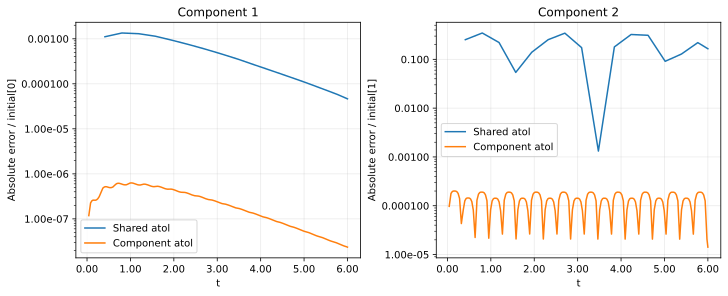

In [8]:
initial = np.array([1.00, 1.00e-6])


def two_components(t, y):
    return np.array([-y[0], -1.00e-5 * np.sin(10 * t)])


cases = {'Shared atol': 1.00e-6,
         'Component atol': np.array([1.00e-6, 1.00e-12])}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for label, atol in cases.items():
    result = adaptive_bs23(two_components, (0, 6), initial, rtol=1.00e-3, atol=atol)
    reference = np.column_stack((np.exp(-result['t']), np.cos(10 * result['t'])))
    relative_to_initial = abs(result['y'] / initial - reference)
    pprint({'設定': label, '関数評価': result['nfev'],
            '初期値で規格化した最大誤差': [sig(v) for v in relative_to_initial.max(axis=0)]})
    for i, ax in enumerate(axes):
        positive = relative_to_initial[:, i] > 0
        ax.semilogy(result['t'][positive], relative_to_initial[positive, i], label=label)
        ax.set(xlabel='t', ylabel=f'Absolute error / initial[{i}]', title=f'Component {i + 1}')
        ax.legend()
save_figure(fig, '05_component_atol.svg')

成分別の設定では、小さい成分の振動に応じて刻みが制限される。その分、関数評価回数も増える。`atol`は単に小さい値を入れるのではなく、各成分に必要な絶対精度から決める値である。

## 7. SciPyのRK23とRK45で計算する

[solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)では許容誤差を指定するだけで刻みが調整される。`t_eval`は出力時刻の指定であり、内部刻みの指定ではない。ここでは省略し、`sol.t`から内部の採用刻みを取り出す。

成分数を $m$ とすると、SciPyの実装は正規化誤差のRMS、$R_{\mathrm{RMS}}=\sqrt{\sum_i r_i^2/m}$ を使う。この記事の最大値ノルムとは多成分の場合に採否が異なる。初期刻みの選択や増減制限も異なるため、計算結果の節点が完全に一致するとは限らない。

[RK45](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.RK45.html)はDormand–Princeの5(4)公式である。4次公式の局所誤差は $O(h^5)$ なので更新指数は $-1/5$ となり、採用値には5次公式を使う。3(2)公式の $-1/3$ と混同しないようにする。

{'手法': 'RK23', '採用': 144, '節点上の最大絶対誤差': '5.89e-06', '関数評価': 467}
{'手法': 'RK45', '採用': 35, '節点上の最大絶対誤差': '1.17e-06', '関数評価': 260}


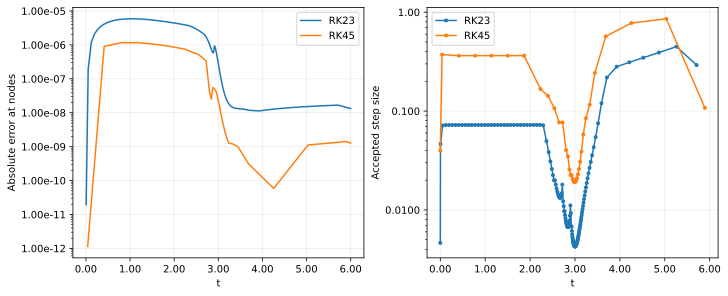

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
solutions = {}
for method in ('RK23', 'RK45'):
    sol = solve_ivp(rhs, (0, 6), [1.00], method=method,
                    rtol=1.00e-5, atol=1.00e-8, max_step=1.00)
    if not sol.success:
        raise RuntimeError(sol.message)
    solutions[method] = sol
    error = abs(sol.y[0] - exact(sol.t))
    pprint({'手法': method, '採用': len(sol.t) - 1, '関数評価': sol.nfev,
            '節点上の最大絶対誤差': sig(error.max())})
    positive = error > 0
    axes[0].semilogy(sol.t[positive], error[positive], label=method)
    axes[1].semilogy(sol.t[:-1], np.diff(sol.t), '.-', label=method)
axes[0].set(xlabel='t', ylabel='Absolute error at nodes')
axes[1].set(xlabel='t', ylabel='Accepted step size')
for ax in axes:
    ax.legend()
save_figure(fig, '06_scipy_comparison.svg')

高い次数が常に有利とは限らないが、この滑らかな問題ではRK45が少ない評価回数で計算できる。硬い問題では誤差制御に加えて陽解法の安定性が刻みを制限する。その場合はRadauやBDFなども選択肢になる。不連続点が既知ならそこで積分区間を分割する。許容値を小さくするだけでは、こうした問題は解消しない。

## 結論

この記事では、埋め込みRunge–Kutta法の局所誤差推定と刻み幅の制御を導出し、Pythonで精度と計算量を確認した。

3(2)公式では2次解との差を $O(h^3)$ の推定値として使い、3次解を採用する。許容誤差は成分の大きさに応じて正規化し、棄却時は出発点を変えずに計算し直す。局所的な採用条件は大域誤差の上限を保証しないため、必要な精度は許容値を変えた再計算でも確認する。

参考文献：P. Bogacki and L. F. Shampine, “A 3(2) Pair of Runge–Kutta Formulas”, Applied Mathematics Letters, 2(4), 321–325, 1989（[SciPyの文献情報](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.RK23.html#references)）。係数と誤差制御の実装は[SciPy公式ソース](https://github.com/scipy/scipy/blob/v1.18.1/scipy/integrate/_ivp/rk.py)、RMSの定義は[共通関数](https://github.com/scipy/scipy/blob/v1.18.1/scipy/integrate/_ivp/common.py)を参照した。